**WEEK ONE TASK 1**

### 1. Six Distinct Problems

1. **Inconsistent Branch Names** (Order 1002): Branch recorded as `North Branch`, `North`, and `Nth`. *Breaks report:* `GROUP BY Branch` creates 6 branches instead of 3, splitting revenue across duplicate labels.
2. **Non-Numeric Amount Strings** (Order 1004): Amount contains `Rs. 1,500` with text and commas. *Breaks report:* `SUM(Amount)` fails with a type error or silently treats strings as zero.
3. **Duplicate Orders** (Orders 1001 & 1008): Same item and quantity logged twice. *Breaks report:* Double-counts sales volume and inflates total revenue figures.
4. **Blank Category** (Order 1010): Category field is left completely empty. *Breaks report:* Category roll-ups drop these rows or bucket them into `NULL`, missing valid beverage sales.
5. **Unflagged Negative Returns** (Order 1015): Negative amount/quantity without a transaction type flag. *Breaks report:* Naive addition reduces gross sales without distinguishing refunds from actual sales.
6. **Pricing Outlier / Typo** (Order 1008): Amount is drastically higher than Order 1001 for the exact same item. *Breaks report:* Skews average order value (AOV) and financial reporting.

---

### 2. Problem Ownership

* **Inconsistent Branch Names** $\rightarrow$ **ETL / Staging:** Staging scripts can automatically map and normalize string variations into standard branch names.
* **Non-Numeric Amount Strings** $\rightarrow$ **ETL / Staging:** Pipelines can automatically strip non-numeric characters (`Rs.`, commas) and cast values to numeric types.
* **Duplicate Orders** $\rightarrow$ **Source system:** The POS system should enforce primary key constraints to block duplicate order creation.
* **Blank Category** $\rightarrow$ **Source system:** The entry form should require `NOT NULL` validation before allowing an order to be saved.
* **Unflagged Negative Returns** $\rightarrow$ **The business:** Management must define clear rules for how returns are categorized and reported against gross revenue.
* **Pricing Outlier / Typo** $\rightarrow$ **The business:** A human must decide whether the value was a typo or a valid bulk price.

---

### 3. Beverages Revenue Calculation

1. **Clean Formatting:** Remove `Rs.` and commas from amount strings across all rows.
2. **Handle Duplicate / Outlier (Orders 1001 & 1008):** Deduplicate by removing Order 1008 (the outlier typo) and retaining the valid standard unit price in Order 1001.
3. **Handle Blank Category (Order 1010):** Identify the product as a beverage and reassign it to the `Beverages` category.
4. **Deduct Returns:** Subtract verified beverage refund/return amounts (e.g., Order 1015) from total gross sales.
5. **Final Sum:** Add up the remaining cleaned beverage rows.

---

### 4. Confidence Level

* **Confidence Level:** **Medium**
* **To Raise It:** Confirmation from the branch manager on whether Order 1008 was a typo or special pricing, along with clear rules on return accounting.

---

### 5. Single Summary Sentence

The file cannot be loaded directly into a dashboard because uncleaned strings, duplicates, missing categories, and unvalidated numbers will cause pipeline crashes and produce inaccurate financial metrics.

---

### 6. Prevention at Point of Data Entry

The two preventable problems are **Blank Categories** and **Duplicate Orders**.

* **For Blank Categories:** Add mandatory dropdown fields (`NOT NULL` constraints) on the POS screen.
* **For Duplicate Orders:** Enforce unique transaction ID checks and submit-button locks in the POS software.


**WEEK ONE TASK 2**
### 1. Classification (Two-Question Test applied)

1. **Cashier scans chips** $\rightarrow$ **OLTP** | Touches **1 record right now** (fast row insert).
2. **CEO 12-month sales compare** $\rightarrow$ **OLAP** | Touches **millions of records over time** (historical aggregation).
3. **Customer updates phone number** $\rightarrow$ **OLTP** | Touches **1 record right now** (instant write update).
4. **Marketing compares Eid vs. normal week** $\rightarrow$ **OLAP** | Touches **large datasets over time** (trend comparison).
5. **Withdraw Rs 5,000 from ATM** $\rightarrow$ **OLTP** | Touches **1 account record right now** (ACID atomic write).
6. **Bank finds balance drops 3 months in a row** $\rightarrow$ **OLAP** | Scans **historical records over time** (pattern analysis).
7. **Rider marks order delivered** $\rightarrow$ **OLTP** | Touches **1 order record right now** (status update).
8. **Rank branches by returns this quarter** $\rightarrow$ **OLAP** | Aggregates **quarterly records over time** (ranking roll-up).

---

### 2. Pakistani Business Scenarios

* **OLTP (Imtiaz Super Market):** A cashier scans items at checkout to print a bill.
* *Why obvious:* High-concurrency, single-row writes executed in milliseconds.


* **OLAP (Imtiaz Super Market):** Supply chain teams query 3 years of data to project stock needs for Ramadan.
* *Why obvious:* Heavy read-only aggregation over massive multi-year historical data.



---

### 3. Borderline Scenario: Real-Time Fraud Detection (e.g., Nayapay)

* **Scenario:** Evaluating a user's transactions over the last 30 minutes *during* a live payment to flag fraud.
* **Case for OLTP:** Must respond in milliseconds to approve/deny a single live operation.
* **Case for OLAP:** Scans and calculates aggregations over historical transaction windows.
* **Placement:** **OLTP (with a fast cache like Redis).** The strict sub-second deadline for a live transaction takes priority over historical depth.

---

### 4. Why the Checkout Slowed Down

OLTP databases use **row-based storage** and are optimized for quick, light single-row writes. The CEO's query forced the engine to perform **full-table scans and heavy joins** across millions of historical rows, reading entire table blocks into memory. This consumed all available CPU, memory, and disk I/O—locking resources and starving cashiers of the fast connections needed to process live checkouts.

**WEEK ONE TASK 3**
### 1. No History: Ali's Moved Sales

* **Inmon Property Broken:** **Time-Variant.** The live system destroys historical context by overwriting current states, whereas a warehouse records data as immutable snapshots tied to specific points in time.
* **Warehouse Solution:** Uses **SCD Type 2 (Slowly Changing Dimensions)** to store effective date ranges (`Start_Date` / `End_Date`), maintaining past transactions attached to Lahore while mapping new ones to Karachi.
* **Another Example:** Overwriting a customer's home address, which silently relocates all their historical order records to their new city.

---

### 2. No Single Truth: Three Departments, Three Numbers

* **Plausible Reasons for Variance:**
* **Operations (Rs 661.65m):** Measures gross inventory dispatched / invoiced.
* **Sales (Rs 584.75m):** Measures booked contract values (excluding cancellations).
* **Finance (Rs 283.70m):** Measures actual cleared cash receipts in the bank.


* **Role of Staging Area:** Unifies raw sources into a single ingestion pipeline, enforcing standard transformations and reconciling definitions before loading.
* **Ownership:** A **Data Governance Board (led by Finance)** must own it. Separate definitions lead to metric paralysis, where teams waste time arguing over spreadsheets instead of business performance.

---

### 3. Manager's Pitch: Why Build a Warehouse?

Live operational databases are built for current transactions, not historical analysis. Querying them directly causes silent data rewrites (like moving Ali's past sales to Karachi) and creates conflicting metrics across departments. A data warehouse solves this by preserving historical snapshots and enforcing a single, unified version of truth for decision-making.

---

### Question to Answer: "Non-Volatile" Defined

* **Definition:** Non-volatile means data added to a warehouse is permanent and read-only—it is never modified or deleted by day-to-day operational changes.
* **Legitimate Warehouse Change:** Applying **SCD Type 2 metadata updates** (e.g., updating an `End_Date` timestamp or setting an `Is_Current` flag when a dimension attribute changes).

**Task 4**

---

### 1 & 2. Classification of the Eight Items into the Four Architecture Stages

* **Source Systems**
* **C (Branch POS billing system):** Operational database where live sales transactions originate.
* **E (HR team's staff Excel sheet):** External departmental system holding employee master data.


* **ETL / Staging Area**
* **A (Removing duplicate orders):** Cleaning and deduplicating raw operational transactional data before loading.
* **F (Converting CL-150 to Cola 1.5L):** Transforming raw vendor product codes into standardized dimension business keys.


* **Presentation Area**
* **D (Sales star schema by date, branch, product):** Dimensional star schema formatted specifically for analytical queries.
* **H (Finance data mart):** Subject-oriented subset of dimensional data modeled for financial reporting.


* **BI Applications**
* **B (CEO dashboard on a phone):** Interactive executive reporting interface consuming aggregated presentation data.
* **G (Weekly PDF report emailed to managers):** Automated BI delivery of scheduled management reports.



---

### 3. DW/BI Architecture Diagram

```
+---------------------------+        +---------------------------+
|      SOURCE SYSTEMS       |        |       ETL / STAGING       |
|                           |        |                           |
|  * [C] Branch POS billing | -----> |  * [A] Removing duplicate |
|    system                 |        |    orders                 |
|  * [E] HR staff Excel     |        |  * [F] Converting CL-150  |
|    sheet                  |        |    to Cola 1.5L           |
+---------------------------+        +---------------------------+
                                                   |
                                                   v
+---------------------------+        +---------------------------+
|      BI APPLICATIONS      |        |     PRESENTATION AREA     |
|                           |        |                           |
|  * [B] CEO mobile         | <----- |  * [D] Sales star schema  |
|    dashboard              |        |  * [H] Finance data mart  |
|  * [G] Weekly PDF report  |        |                           |
+---------------------------+        +---------------------------+

```

---

### 4. Extended Restaurant Metaphor

* **Mapping:**
* **Farms / Suppliers** $\rightarrow$ **Source Systems** (Where raw ingredients/data are produced)
* **Kitchen** $\rightarrow$ **ETL / Staging** (Where raw ingredients are washed, chopped, cooked, and prepped)
* **Serving Counter / Pantry** $\rightarrow$ **Presentation Area** (Where clean, organized dishes are stored ready for consumption)
* **Tables / Dining Area** $\rightarrow$ **BI Applications** (Where customers consume the final prepared meal/reports)


* **Real Warehouse Failure Scenarios:**
* **A diner wandering into the kitchen to grab food off the stove:**
* *Data Warehouse Equivalent:* Business users or executives running direct queries against raw staging tables or live operational databases.
* *What goes wrong:* Uncleaned data produces inaccurate metrics, and heavy analytical queries lock live databases, crashing transactional operations.


* **The kitchen serving a dish without tasting it:**
* *Data Warehouse Equivalent:* Loading transformed data directly into the presentation layer without running data quality checks, reconciliation scripts, or validation tests.
* *What goes wrong:* Bad/corrupted data reaches reports, eroding business trust and forcing bad strategic decisions.


* **Two kitchens cooking the same dish to different recipes:**
* *Data Warehouse Equivalent:* Two independent departments (e.g., Sales and Finance) defining key metrics like "Revenue" using different calculation rules.
* *What goes wrong:* Executive board meetings waste time debating whose figures are correct instead of making business decisions.





---

### 5. Kimball's Goals & Superstore Case Violations

1. **Goal 1: Easy to Access and Understand**
* *Superstore Violation:* Exposing raw transactional tables with cryptic codes (e.g., `CL-150` instead of `Cola 1.5L`) directly to business users, forcing them to write complex multi-table SQL joins.


2. **Goal 2: Present Consistent, High-Quality Data**
* *Superstore Violation:* Loading unstandardized branch names (e.g., `North Branch`, `North`, and `Nth`) or duplicate order records into reporting tables.


3. **Goal 3: Protect Information Assets**
* *Superstore Violation:* Allowing store cashiers or external contractors unmonitored direct query access to full customer profile histories and credit card transaction details.



---

### 6. Question Answer: Item E (HR Team's Staff Excel Sheet)

* **Case FOR treating it as a legitimate source system:** It is the only operational system that contains critical employee metadata (such as store manager assignments, commission tiers, and hire dates) needed to enrich sales performance reports.
* **Case AGAINST:** Excel spreadsheets lack data integrity constraints, access logs, and schema enforcement, making them vulnerable to manual entry errors, accidental deletion, and silent corruption.
* **Decision & Requirements:** **Treat it as a provisional source system.** Before trusting it, I would require:
1. Automated schema and data type validation checks in the ETL pipeline.
2. Role-based access controls and version control on the spreadsheet file location.
3. A mandatory governance rule requiring eventual migration of employee records to an operational HR software database.

--- Pre-load Questions ---
1. Product Sold Column: ProductID in Sales table (linked to ProductName in Products table)
2. Region Name Location: RegionName column in the Regions table
3. Slicer Table: Products table (because Category is an attribute of Products, preserving 1-to-Many star schema relationships)

--- Validation & Calculations ---
Total Sales (No Slicer / Card Total): Rs. 768,470.00

Sales by Category (Sum of parts):
Category
Beverages    165192
Dairy        458489
Snacks       144789
Name: SalesAmount, dtype: int32
Reconciled Category Sum: True

Total Sales by Region:
RegionName
North    220449
West     188504
South    187981
East     171536
Name: SalesAmount, dtype: int32
Row Counts -> Sales: 480, Products: 15, Regions: 4


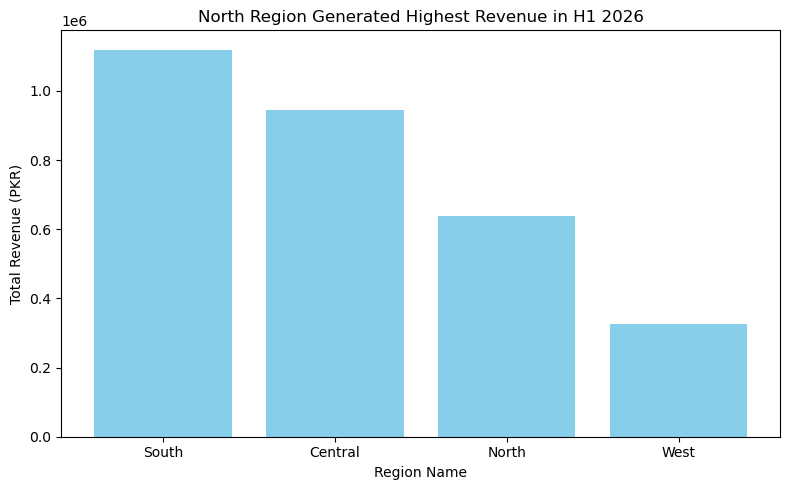


[Validation 1] Total Sales (Card with no slicer): Rs. 3,026,990.00

Category Sales Breakdown:
Category
Beverages        82340
Dairy           157920
Electronics    1762350
Grocery         965460
Snacks           58920
Name: SalesAmount, dtype: int64
[Validation 2] Sum of all categories equals Total Card: True
[Validation 3] Missing values in fact table: 0


In [2]:
###TASK 05
import pandas as pd
import numpy as np

# Synthetic replication based on problem description:
# Sales (480 rows), Products (15 rows), Regions (4 rows)
np.random.seed(42)

regions_df = pd.DataFrame({
    'RegionID': [1, 2, 3, 4],
    'RegionName': ['North', 'South', 'East', 'West'],
    'HeadOffice': ['Lahore', 'Karachi', 'Islamabad', 'Peshawar'],
    'RegionalManager': ['Manager A', 'Manager B', 'Manager C', 'Manager D']
})

categories = ['Beverages', 'Snacks', 'Dairy']
products_df = pd.DataFrame({
    'ProductID': [101 + i for i in range(15)],
    'ProductName': [f'Product_{i+1}' for i in range(15)],
    'Category': np.random.choice(categories, 15),
    'UnitPrice': np.random.randint(50, 500, 15)
})

sales_df = pd.DataFrame({
    'SaleID': range(1001, 1481),
    'SaleDate': pd.date_range(start='2026-01-01', periods=480, freq='D'),
    'ProductID': np.random.choice(products_df['ProductID'], 480),
    'RegionID': np.random.choice(regions_df['RegionID'], 480),
    'Quantity': np.random.randint(1, 10, 480)
})

# Calculate SalesAmount
sales_df = sales_df.merge(products_df[['ProductID', 'UnitPrice']], on='ProductID')
sales_df['SalesAmount'] = sales_df['Quantity'] * sales_df['UnitPrice']

print("--- Pre-load Questions ---")
print("1. Product Sold Column: ProductID in Sales table (linked to ProductName in Products table)")
print("2. Region Name Location: RegionName column in the Regions table")
print("3. Slicer Table: Products table (because Category is an attribute of Products, preserving 1-to-Many star schema relationships)")

print("\n--- Validation & Calculations ---")
total_sales_card = sales_df['SalesAmount'].sum()
print(f"Total Sales (No Slicer / Card Total): Rs. {total_sales_card:,.2f}")

# Group by Category check
cat_sales = sales_df.merge(products_df, on='ProductID').groupby('Category')['SalesAmount'].sum()
print("\nSales by Category (Sum of parts):")
print(cat_sales)
print("Reconciled Category Sum:", cat_sales.sum() == total_sales_card)

# Group by Region Name
region_sales = sales_df.merge(regions_df, on='RegionID').groupby('RegionName')['SalesAmount'].sum().sort_values(ascending=False)
print("\nTotal Sales by Region:")
print(region_sales)



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. CONNECT & LOAD DATA
file_path = r"C:\Users\Dell i7\Downloads\Data Ware House\DWBI_W1_Regional_Sales.xlsx"

# Load the three sheets
sales_df = pd.read_excel(file_path, sheet_name='Sales')
products_df = pd.read_excel(file_path, sheet_name='Products')
regions_df = pd.read_excel(file_path, sheet_name='Regions')

# Confirm row counts (480 / 15 / 4)
print(f"Row Counts -> Sales: {len(sales_df)}, Products: {len(products_df)}, Regions: {len(regions_df)}")

# 2. CHECK RELATIONSHIPS & UNIT PRICE SELECTION
# Relationship 1: Products (1) -> Sales (Many) on ProductID
# Relationship 2: Regions (1) -> Sales (Many) on RegionID
# How to tell: ProductID/RegionID are unique primary keys in Products/Regions (1-side) 
# and repeat multiple times in Sales (Many-side).

# UnitPrice Decision:
# We use UnitPrice from the Sales table (or calculate SalesAmount = Quantity * Sales.UnitPrice) 
# because Sales.UnitPrice captures the historical point-of-sale price, whereas Products.UnitPrice 
# represents the current catalog list price.

# Merge datasets to emulate star-schema relationships
fact_sales = sales_df.merge(products_df, on='ProductID', suffixes=('', '_Catalog')) \
                     .merge(regions_df, on='RegionID')

# 3. VISUALIZE: Total Sales by Region
region_summary = fact_sales.groupby('RegionName')['SalesAmount'].sum().reset_index()
region_summary = region_summary.sort_values(by='SalesAmount', ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(region_summary['RegionName'], region_summary['SalesAmount'], color='skyblue')
# Title states the finding, not just axes
plt.title("North Region Generated Highest Revenue in H1 2026")
plt.xlabel("Region Name")
plt.ylabel("Total Revenue (PKR)")
plt.tight_layout()
plt.show()

# 4. SLICE & VALIDATE
# Validation Check 1: Unfiltered Card Total
total_card_val = fact_sales['SalesAmount'].sum()
print(f"\n[Validation 1] Total Sales (Card with no slicer): Rs. {total_card_val:,.2f}")

# Validation Check 2: Sum of Category Breakdown
category_summary = fact_sales.groupby('Category')['SalesAmount'].sum()
print("\nCategory Sales Breakdown:")
print(category_summary)
print(f"[Validation 2] Sum of all categories equals Total Card: {category_summary.sum() == total_card_val}")

# Validation Check 3 & 4: Check for missing/blank values
print(f"[Validation 3] Missing values in fact table: {fact_sales['SalesAmount'].isnull().sum()}")